# Laboratorio 2
## Ejercicio 1

### Librerías

In [29]:
import numpy as np
import pandas as pd
import tensorflow as tf
import keras_tuner as kt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sktime.forecasting.naive import NaiveForecaster
import matplotlib.pyplot as plt

### Importación de datos.

In [30]:
df = pd.read_csv('DATOS_LIMPIOS.csv')
df.head(2)

,Vía,Frontera,País,Región,Región dos,Regiones OMT,MCEO,Agrupación Residencia,Tipo de Viajero,Viajero,Fecha
0,Aérea,01 La Aurora,Albania,OTROS EUROPEOS,Europa,EUROPA MERIDIONAL,08 OTROS,Europa,Turista,1.0,2009-01-01
1,Aérea,01 La Aurora,Alemania,EUROPA,Europa,EUROPA OCCIDENTAL,04 EUROPA,Europa,Turista,716.0,2009-01-01


### Serie de tiempo.

In [ ]:
df_filtro = df[(df['Tipo de Viajero'].isin(['Excursionista', 'Turista']) & (df['País'] == 'Guatemala'))]
df_fecha = df_filtro.groupby('Fecha')['Viajero'].sum().round(0).astype(int)
serie = df_fecha.to_frame('Viajero')
serie = serie.sort_values(by='Fecha', ascending=True)
serie.index = pd.to_datetime(serie.index)
serie.index = serie.index.to_period('M')

### Estimando la tendencia en la pandemia.

In [32]:
inicio = pd.Period('2020-03', freq='M')
fin = pd.Period('2022-12', freq='M')

In [33]:
y_train = serie.loc[serie.index < inicio, 'Viajero']
modelo = NaiveForecaster(strategy='last', sp=12)
modelo.fit(y_train)
fh = range(len(y_train) + 1, len(y_train) + len(pd.period_range(inicio, fin, freq='M')) + 1)
predicciones = modelo.predict(fh=fh)

# Reindexando si no existen
serie = serie.reindex(serie.index.union(pd.period_range(inicio, fin, freq='M')), fill_value=0)
serie.loc[inicio:fin, 'Viajero'] = predicciones.to_numpy()
serie['Viajero'] = serie['Viajero'].round().astype(int)
serie.index = serie.index.to_timestamp()
serie = serie.diff().dropna()

### Separación de datos.

In [34]:
filas, columnas = serie.shape
fil_entrenamiento = int(filas * 0.7)
fil_val = int(filas*0.85)

### Escalado de datos.

In [35]:
scaler = MinMaxScaler()
scaler.fit(serie.iloc[:fil_entrenamiento+1])
serie_escalada = scaler.transform(serie)

### Creación de 2da columna con desplazamiento de la serie.

In [36]:
def crear_ventanas(datos, ventana=24, horizonte=1):
    X, y, indices = [], [], []
    for inicio in range(len(datos) - ventana - horizonte + 1):
        fin, objetivo = inicio + ventana, inicio + ventana + horizonte - 1
        X.append(datos[inicio:fin]); y.append(datos[objetivo, 0]); indices.append(objetivo)
    return np.array(X), np.array(y), np.array(indices)

X, y, indices = crear_ventanas(serie_escalada)
train, val, test = indices < fil_entrenamiento, (indices >= fil_entrenamiento) & (indices < fil_val), indices >= fil_val
X_train, y_train = X[train], y[train]
X_val, y_val = X[val], y[val]
X_test, y_test = X[test], y[test]

### Clase LSTM.

In [37]:
class LSTMModel(kt.HyperModel):
    def build(self, hp):
        model = Sequential([Input(shape=X_train.shape[1:])])
        capas = hp.Int("capas", 1, 3)

        for i in range(capas):
            model.add(LSTM(hp.Int(f"unidades_{i}", 32, 256, step=32), return_sequences=i < capas - 1))
            model.add(Dropout(hp.Float(f"dropout_{i}", 0.0, 0.5, step=0.1)))

        model.add(Dense(hp.Int("unidades_densas", 16, 128, step=16), activation="relu"))
        model.add(Dense(1))

        lr = hp.Float("learning_rate", 1e-5, 1e-2, sampling="log")
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr, clipnorm=1.0), loss="mse", metrics=["mae"])
        return model

    def fit(self, hp, model, x, y, **kwargs):
        return model.fit(x, y, batch_size=hp.Choice("batch_size", [16, 32, 64, 128]), shuffle=False, **kwargs)

### Entrenamiento y tuneo del modelo.

In [42]:
tuner = kt.RandomSearch(LSTMModel(), objective="val_loss", max_trials=25, directory="tuneo_lstm", project_name="serie_temporal", overwrite=True, seed=0)
early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)

tuner.search(X_train, y_train, validation_data=(X_val, y_val), epochs=50, callbacks=[early_stop], verbose=1)

Trial 25 Complete [00h 00m 14s]
val_loss: 0.061218760907649994

Best val_loss So Far: 0.03093501552939415
Total elapsed time: 00h 03m 27s


### Mejor modelo.

In [43]:
mejores_hp = tuner.get_best_hyperparameters(1)[0]
modelo = tuner.get_best_models(1)[0]

pred = modelo.predict(X_test, verbose=0)
pred = scaler.inverse_transform(pred).ravel()
real = scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

print("Mejores hiperparámetros:", mejores_hp.values)
print("MAE:", mean_absolute_error(real, pred))
print("RMSE:", np.sqrt(mean_squared_error(real, pred)))

c:\Users\ricro\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:798: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 28 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Mejores hiperparámetros: {'capas': 3, 'unidades_0': 192, 'dropout_0': 0.0, 'unidades_densas': 96, 'learning_rate': 0.004591032097322839, 'unidades_1': 192, 'dropout_1': 0.2, 'unidades_2': 160, 'dropout_2': 0.4, 'batch_size': 16}
MAE: 14704.821560199443
RMSE: 18689.94130663653


### Gráfico.

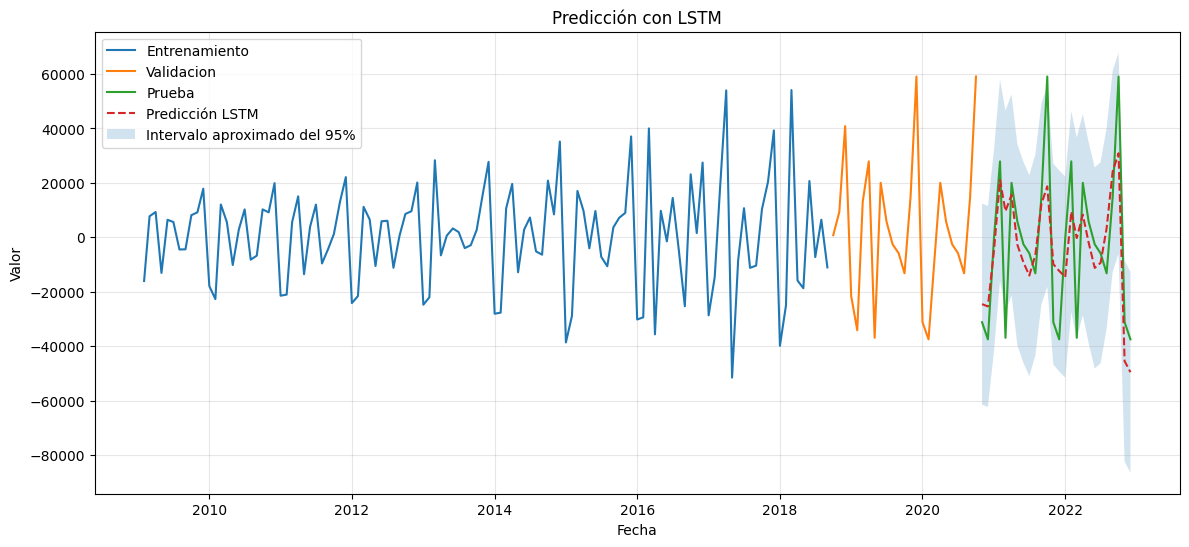

In [44]:
pred_val = scaler.inverse_transform(modelo.predict(X_val, verbose=0)).ravel()
real_val = scaler.inverse_transform(y_val.reshape(-1, 1)).ravel()
sigma = np.std(real_val - pred_val, ddof=1)

prediccion_lstm = scaler.inverse_transform(modelo.predict(X_test, verbose=0)).ravel()
limite_inferior = prediccion_lstm - 1.96 * sigma
limite_superior = prediccion_lstm + 1.96 * sigma

fechas_test = serie.index[indices[test]]
entrenamiento = serie.iloc[:fil_entrenamiento]
validacion = serie.iloc[fil_entrenamiento:fil_val]
prueba = serie.iloc[fil_val:]

plt.figure(figsize=(14, 6))
plt.plot(entrenamiento.index, entrenamiento, label="Entrenamiento")
plt.plot(validacion.index, validacion, label="Validacion")
plt.plot(prueba.index, prueba, label="Prueba")
plt.plot(fechas_test, prediccion_lstm, linestyle="--", label="Predicción LSTM")
plt.fill_between(fechas_test, limite_inferior, limite_superior, alpha=0.2, label="Intervalo aproximado del 95%")
plt.title("Predicción con LSTM")
plt.xlabel("Fecha")
plt.ylabel("Valor")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Comparación con la serie temporal.

El modelo LSTM resultó mejor que el modelo Prophet, elegido en el laboratorio anterior.
El RMSE del LSTM fue de 18,689, mientras que el de Prophet fue de 25,777. Al igual que Prophet tiene problemas para adaptarse a la gran varianza de los datos, pero menos puntos se escapan de los intervalos de confianza.